# A3 Échelle et mesure des traits racinaires

La demande : passer des masques prédits à des **mesures en millimètres** (longueur et diamètre des racines), avec une précision connue. Tout se règle sur le **val corrigé** (masques corrigés à la main) ; la mesure finale se fera sur le test (notebook 07).

**L'essentiel**
- **L'échelle annoncée par PRMI (150 DPI, 5,9 px/mm) est fausse** : des images prises tous les 13,5 mm devraient se recouvrir largement à cette échelle, et elles ne se recouvrent pas. Une image couvre un cadre d'environ 18 x 13,5 mm : **40,9 px/mm**. Sans cette vérification, toutes les mesures en mm auraient été fausses d'un facteur 7.
- **Diamètre** : mesuré le long du squelette, juste à 2 % près en moyenne (erreur médiane de 13 % par image).
- **Longueur** : sous-estimée de 17 % ; la méthode de mesure n'y est pour rien (élaguer ou reconnecter ne change rien), ce sont des racines que le modèle ne détecte pas (15 % de la longueur de référence).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.morphology import skeletonize
from scipy import ndimage as ndi

from prmi import blob_classifier as bc, traits as tr, viz
from prmi.dataset import MASKS_DIR, load_lot
from prmi.inventory import RAW
from prmi.train import RUNS_DIR, full_logits, load_run

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_tout'

## 1. L'échelle

Les métadonnées de PRMI annoncent 150 DPI pour nos images, soit 5,9 pixels par millimètre (image de 125 x 94 mm). Or l'article qui décrit l'acquisition précise que les images sont prises **tous les 13,5 mm** le long du tube, avec une caméra Bartz BTC-100X dont le cadre fait environ 18 x 13,5 mm. Les deux ne peuvent pas être vrais à la fois : à 5,9 px/mm, deux positions voisines se recouvriraient à 86 %.

**Test** : pour des paires de positions consécutives (même tube, même date), on cherche le décalage qui superpose au mieux leurs masques de racines. Si les images se recouvraient, ces paires montreraient toutes un décalage d'environ 80 px (13,5 mm à 5,9 px/mm) dans la même direction. Témoin : des paires prises au hasard dans des tubes différents.

{'au hasard': '2% des paires au décalage attendu', 'consécutives': '4% des paires au décalage attendu'}


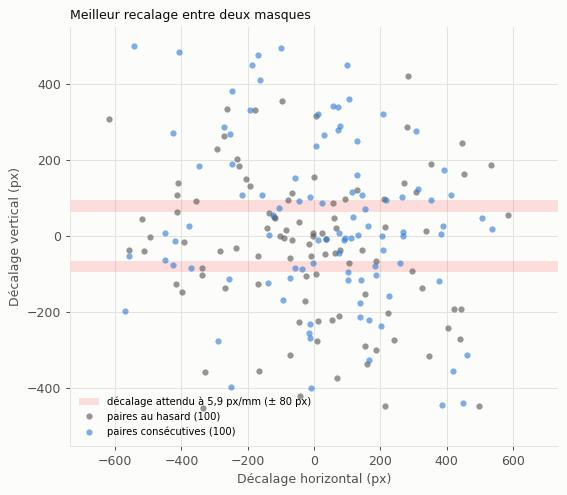

In [2]:
stats = pd.read_parquet('../data/interim/image_stats.parquet')
stats = stats[(stats['dpi'] == 150) & (stats['split'] == 'train') & stats['has_root'] & (stats['root_frac'] > 0.005)]
read_mask = lambda p: np.asarray(Image.open(RAW / p))[..., 0] > 0
shifts = tr.overlap_test(stats, read_mask, n=100)        # environ 2 min, clé branchée
near = lambda s: (((s['dy'].abs() - 80).abs() <= 15) & (s['dx'].abs() <= 15)) | (((s['dx'].abs() - 80).abs() <= 15) & (s['dy'].abs() <= 15))
print({k: f'{near(s).mean():.0%} des paires au décalage attendu' for k, s in shifts.groupby('paires')})
viz.save(viz.plot_overlap(shifts, 80), 'A3_echelle_recouvrement.png');

Les paires consécutives ne se regroupent pas autour du décalage attendu : pas plus que des paires au hasard. **Les images voisines ne se recouvrent pas** : une image couvre donc un cadre d'environ 18 x 13,5 mm, soit **40,9 px/mm** (736 / 18 et 552 / 13,5 : les pixels sont carrés, ce qui conforte l'hypothèse). Pour le capteur « 120 DPI » (640 x 480 px), même cadre : 35,6 px/mm.

**Contrôle de vraisemblance** : diamètre des racines annotées, converti avec chacune des deux échelles.

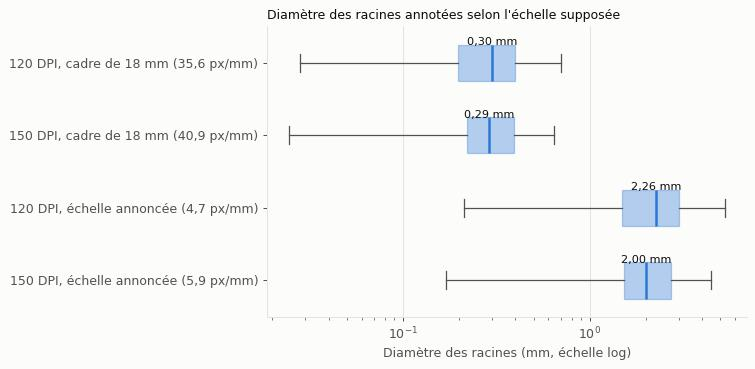

In [3]:
w150 = np.concatenate([tr.skeleton_widths(np.asarray(Image.open(p).convert('L')) > 127)
                       for p in sorted((MASKS_DIR / 'train').glob('GT_*.png'))])
s120 = pd.read_parquet('../data/interim/image_stats.parquet')
s120 = s120[(s120['dpi'] == 120) & (s120['split'] == 'train') & s120['has_root']].sample(150, random_state=0)
w120 = np.concatenate([tr.skeleton_widths(read_mask(p)) for p in s120['mask_path']])
diam = {'150 DPI, échelle annoncée (5,9 px/mm)': w150 / 5.9, '120 DPI, échelle annoncée (4,7 px/mm)': w120 / (120 / 25.4),
        f'150 DPI, cadre de 18 mm ({tr.px_per_mm(150):.1f} px/mm)'.replace('.', ','): w150 / tr.px_per_mm(150),
        f'120 DPI, cadre de 18 mm ({tr.px_per_mm(120):.1f} px/mm)'.replace('.', ','): w120 / tr.px_per_mm(120)}
viz.save(viz.plot_scale(diam), 'A3_echelle_diametres.png');

Avec l'échelle annoncée, les racines feraient 1,5 à 2,3 mm de diamètre en médiane, très épais pour l'arachide, et les deux capteurs ne s'accordent pas. Avec le cadre de 18 mm, on obtient 0,29 et 0,30 mm, l'ordre de grandeur des racines fines d'arachide, et **les deux capteurs s'accordent**, alors qu'ils viennent de sites et d'années différents. **Échelle retenue : 40,9 px/mm (150 DPI) et 35,6 px/mm (120 DPI).** Incertitude d'environ 4 % (cadre de 13 ou 13,5 mm de haut selon les sources).

## 2. Mesurer une racine

Sur le masque prédit (U-Net + classifieur des taches, version 1.1) :
- **longueur** : squelette du masque (sa ligne centrale), chaque pas diagonal comptant pour racine de 2 ;
- **diamètre** : deux fois la distance au bord du masque, le long du squelette ; diamètre moyen d'une image = moyenne le long du squelette.

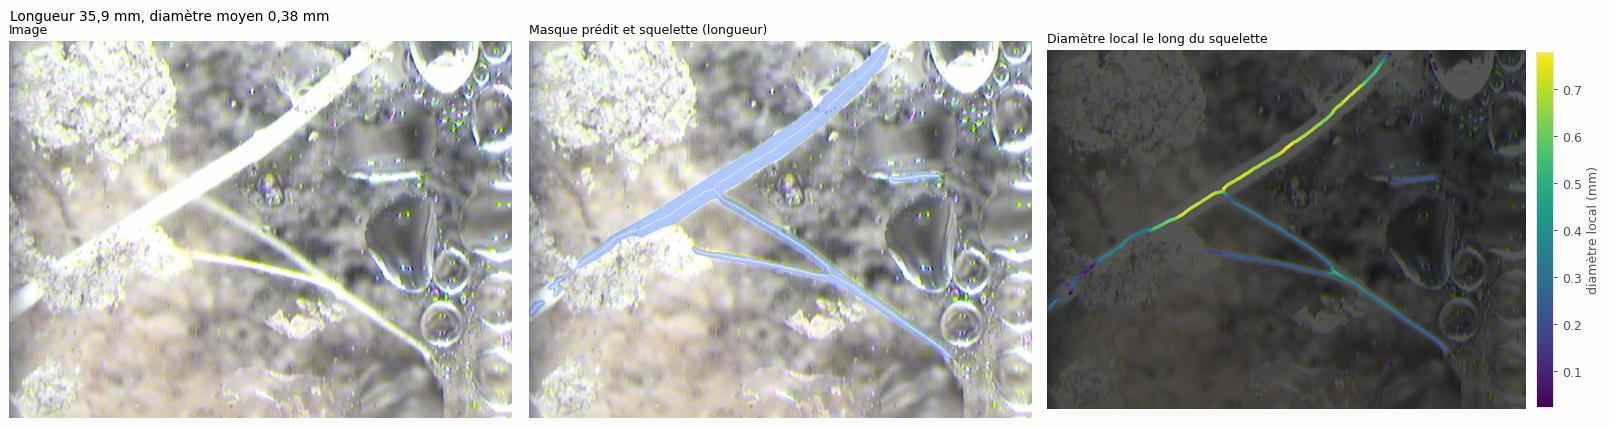

In [4]:
model = load_run(NAME)[0]
device = next(model.parameters()).device
clf, TAU = bc.load(RUNS_DIR / NAME / 'classifieur_taches.joblib')
PPM = tr.px_per_mm(150)
items = [it for it in load_lot('val', 2) if it['mask_full'].any()]
with torch.no_grad():
    probs = [torch.sigmoid(full_logits(model, it, device)[0])[0, 0].cpu().numpy() for it in items]
preds = [bc.classifier_filter(p, clf, TAU) for p in probs]
refs = [it['mask_full'] for it in items]

k = int(np.argmax([r.sum() for r in refs[:20]]))
img = np.asarray(Image.open(Path('../data/interim/qupath/val') / items[k]['name'] / 'image.jpg').convert('RGB'))
m = tr.measure(preds[k])
viz.save(viz.plot_measure(img, preds[k], skeletonize(preds[k]), ndi.distance_transform_edt(preds[k]), PPM,
                          f"Longueur {m['longueur'] / PPM:.1f} mm, diamètre moyen {m['diametre'] / PPM:.2f} mm".replace('.', ',')),
         'A3_mesure_exemple.jpg')

## 3. Précision sur le val corrigé

46 images avec racine, mesures sur la prédiction et sur le masque corrigé à la main, avec la même méthode. Deux corrections ont été essayées sur la longueur : **élaguer** les petites branches du squelette (moins de 20 px) et **reconnecter** les morceaux d'une racine prédite en pointillés (extrémités qui se font face à moins de 40 px).

In [5]:
settings = {'squelette seul': {}, 'élagage (20 px)': {'min_branch': 20}, 'reconnexion (40 px)': {'max_gap': 40},
            'élagage et reconnexion': {'min_branch': 20, 'max_gap': 40}}
tables = {k: tr.compare(preds, refs, PPM, **kw) for k, kw in settings.items()}
pd.DataFrame({k: {**tr.errors(t), 'ponts ajoutés': int(t['ponts'].sum())} for k, t in tables.items()}).T.round(3)

,longueur : erreur médiane,longueur : biais,diamètre : erreur médiane,diamètre : biais,ponts ajoutés
squelette seul,0.157,-0.167,0.128,0.019,0.0
élagage (20 px),0.157,-0.165,0.130,0.017,0.0
reconnexion (40 px),0.157,-0.164,0.128,0.019,6.0
élagage et reconnexion,0.157,-0.162,0.130,0.016,6.0


Élaguer et reconnecter ne changent presque rien : les masques prédits sont lisses, et il n'y a que quelques ponts à faire. D'où vient alors la longueur manquante ?

longueur de référence sans prédiction à moins de 3 px (racines manquées) : 14.9%
longueur prédite sans référence à moins de 3 px (en trop) : 2.7%


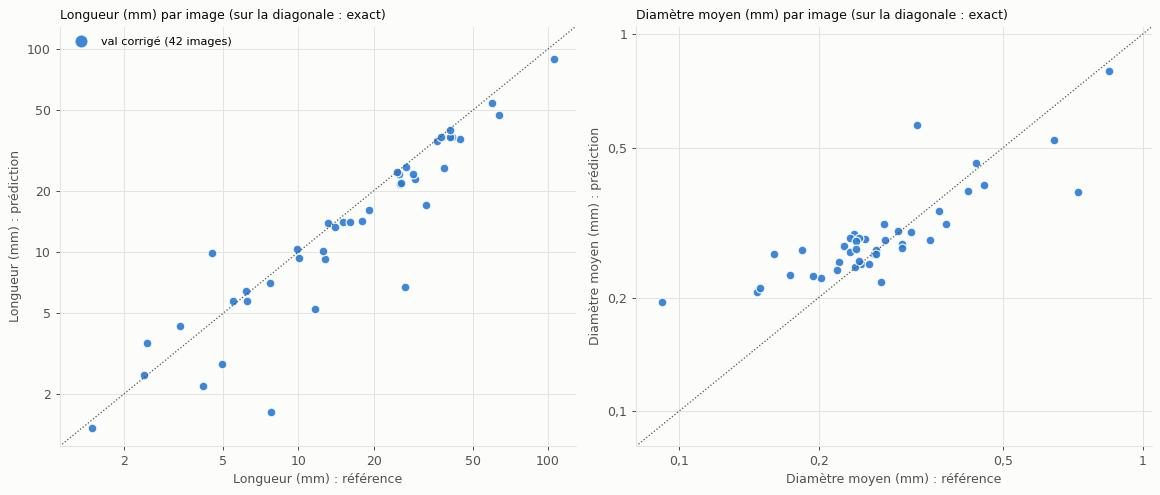

In [6]:
parts = pd.DataFrame([tr.missed_extra(p, r) for p, r in zip(preds, refs)]).sum()
print(f"longueur de référence sans prédiction à moins de 3 px (racines manquées) : {parts['manquée'] / parts['référence']:.1%}")
print(f"longueur prédite sans référence à moins de 3 px (en trop) : {parts['en trop'] / parts['prédite']:.1%}")
viz.save(viz.plot_traits({'val corrigé': tables['squelette seul']}, unit='mm'), 'A3_traits_val.png')

**À retenir**
- **Chaîne retenue** : longueur = squelette du masque prédit (pas diagonaux à racine de 2), sans élagage ni reconnexion, qui n'apportent rien sur ces masques ; diamètre = deux fois la distance au bord le long du squelette ; conversion à 40,9 px/mm (35,6 px/mm en 120 DPI). Code : `src/prmi/traits.py`.
- **Précision sur le val corrigé** (46 images) : diamètre moyen juste à +1,9 % près (erreur médiane 13 % par image) ; longueur sous-estimée de 16,7 % (erreur médiane 16 % par image).
- **La longueur manquante vient de la détection** : 15 % de la longueur de référence n'a aucune prédiction à proximité (racines fines ou peu visibles manquées), contre 3 % de longueur prédite en trop. Pour aller plus loin, il faut améliorer la segmentation elle-même, pas la mesure.
- **Diamètre** : les racines très fines sont un peu surestimées et les plus grosses un peu sous-estimées (le modèle travaille à demi-résolution), sans biais d'ensemble notable.
- **Pour des totaux par tube ou par date**, un facteur d'étalonnage de la longueur (environ 1,2) est envisageable ; il sera vérifié une fois sur le test (notebook 07) avant d'être proposé.